# let's map the snt task

In [40]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
sns.set()

In [2]:
def load_snt_ranges(snt_range_path):
    data = np.load(snt_range_path, allow_pickle=True)
    data = data.item()
    
    species_ids = data["taxa"]
    loc_indices_per_species = data["loc_indices_per_species"]
    labels_per_species = data["labels_per_species"]
    obs_locs = data["obs_locs"]
    
    return obs_locs, species_ids, loc_indices_per_species, labels_per_species

In [4]:
obs_locs, species_ids, loc_indices_per_species, labels_per_species = load_snt_ranges("/home/alex/sinr/data/eval/snt/snt_res_5.npy")

In [22]:
taxon_index = 0
target_taxon_id = species_ids[taxon_index]
cur_loc_indices = np.array(loc_indices_per_species[taxon_index])
y_test = np.array(labels_per_species[taxon_index])
taxon_obs_locs = obs_locs[cur_loc_indices]

In [23]:
taxon_obs_locs[y_test==0]

array([[ 11.927741,  62.76889 ],
       [ 12.061964,  62.87632 ],
       [ 12.089678,  62.680466],
       ...,
       [-38.982666, -16.542051],
       [-39.427704, -16.459286],
       [-39.280216, -16.54078 ]], dtype=float32)

In [25]:
taxon_obs_locs[y_test==1]

array([[-88.06453 ,  38.8073  ],
       [-87.990524,  35.879936],
       [-87.81479 ,  35.9196  ],
       ...,
       [-39.285534, -16.86305 ],
       [-39.137978, -16.944138],
       [-39.42501 , -16.297745]], dtype=float32)

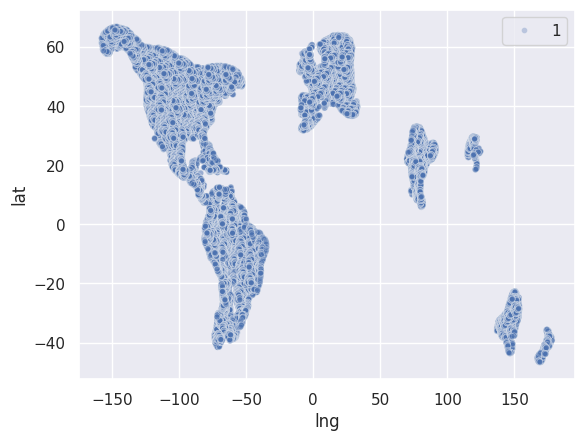

In [51]:
true_negatives = pd.DataFrame(
    taxon_obs_locs[y_test==0],
    columns=["lng", "lat"]
)
sns.scatterplot(
    true_negatives,
    x="lng", 
    y="lat",
    size=1,
    alpha=0.3
)

plt.show()

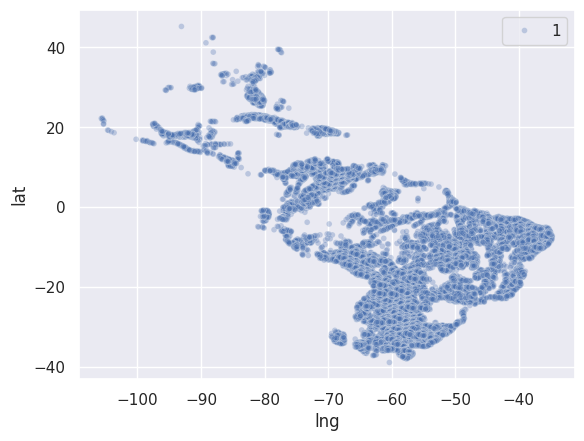

In [52]:
true_positives = pd.DataFrame(
    taxon_obs_locs[y_test==1],
    columns=["lng", "lat"]
)
sns.scatterplot(
    true_positives,
    x="lng", 
    y="lat",
    size=1,
    alpha=0.3
)

plt.show()

In [53]:
snt_df = pd.DataFrame(
    taxon_obs_locs,
    columns=["lng", "lat"]
)
snt_df["label"] = y_test

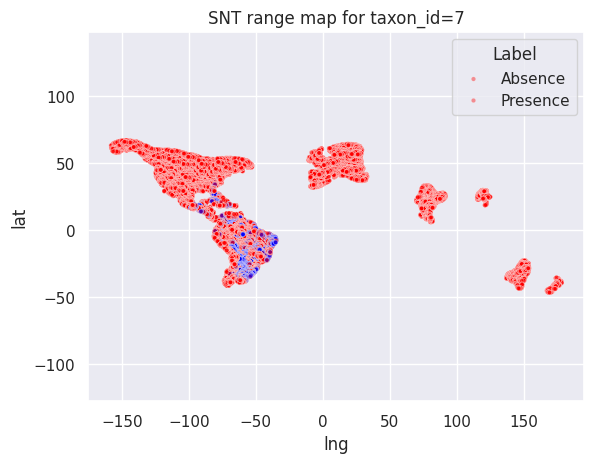

In [55]:
sns.scatterplot(
    data=snt_df,
    x="lng", y="lat",
    hue="label",
    palette={0: "red", 1: "blue"},
    alpha=0.4,
    s=10
)
plt.title(f"SNT range map for taxon_id={target_taxon_id}")
plt.legend(title="Label", labels=["Absence", "Presence"])
plt.axis("equal")
plt.show()

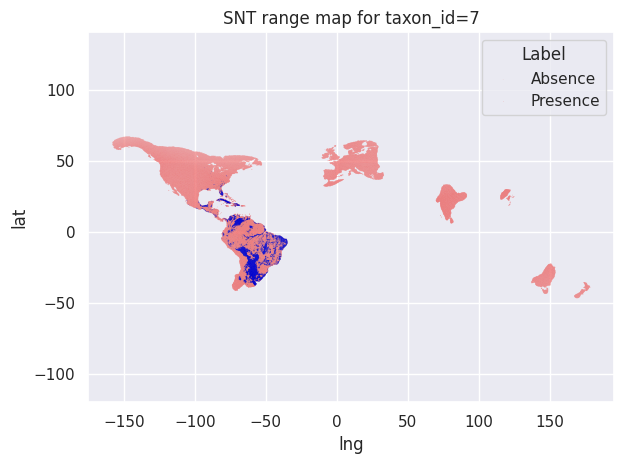

In [61]:
sns.scatterplot(
    data=snt_df,
    x="lng", y="lat",
    hue="label",
    palette={0: "lightcoral", 1: "mediumblue"},  # more visually distinct
    alpha=0.6,
    s=0.1,
    linewidth=0,
    edgecolor=None,
)
plt.title(f"SNT range map for taxon_id={target_taxon_id}")
plt.legend(title="Label", labels=["Absence", "Presence"], loc="upper right")
plt.axis("equal")
plt.tight_layout()
plt.show()

# let's try another taxon

In [62]:
taxon_index = 53
target_taxon_id = species_ids[taxon_index]
cur_loc_indices = np.array(loc_indices_per_species[taxon_index])
y_test = np.array(labels_per_species[taxon_index])
taxon_obs_locs = obs_locs[cur_loc_indices]

In [63]:
snt_df = pd.DataFrame(
    taxon_obs_locs,
    columns=["lng", "lat"]
)
snt_df["label"] = y_test

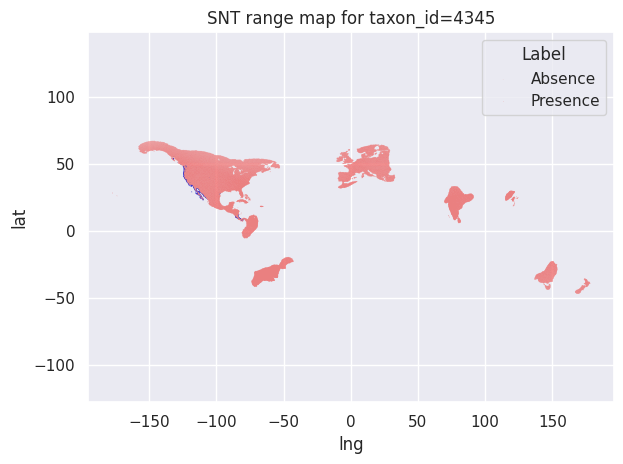

In [64]:
sns.scatterplot(
    data=snt_df,
    x="lng", y="lat",
    hue="label",
    palette={0: "lightcoral", 1: "mediumblue"},  # more visually distinct
    alpha=0.6,
    s=0.1,
    linewidth=0,
    edgecolor=None,
)
plt.title(f"SNT range map for taxon_id={target_taxon_id}")
plt.legend(title="Label", labels=["Absence", "Presence"], loc="upper right")
plt.axis("equal")
plt.tight_layout()
plt.show()

# let's do this in h3

In [85]:
import h3
import h3pandas
import pandas as pd
import geopandas as gpd

from matplotlib.colors import ListedColormap

In [70]:
h3_res = 4

# Create a DataFrame for convenience
df = pd.DataFrame(taxon_obs_locs, columns=["lng", "lat"])
df["label"] = y_test
dfh3 = df.h3.geo_to_h3(h3_res)
dfh3.reset_index(inplace=True)

In [71]:
dfh3

,h3_04,lng,lat,label
0,8408101ffffffff,11.927741,62.768890,0
1,8408101ffffffff,12.061964,62.876320,0
2,8408101ffffffff,12.089678,62.680466,0
3,8408101ffffffff,12.224094,62.787971,0
4,8408101ffffffff,11.631933,62.749199,0
...,...,...,...,...
127498,84478ddffffffff,-174.108902,26.128294,0
127499,8447a35ffffffff,-177.472351,28.297066,0
127500,8447a35ffffffff,-177.291534,28.273949,0
127501,8447a35ffffffff,-177.408112,28.145657,0


In [72]:
counts = dfh3.groupby(["h3_04", "label"]).size().unstack(fill_value=0).reset_index()
counts.columns.name = None
counts = counts.rename(columns={0: "absence", 1: "presence"})

# Optional: compute net label (e.g. whichever dominates the cell)
counts["dominant_label"] = counts["presence"] > counts["absence"]

In [80]:
gdf = counts.set_index("h3_04").h3.h3_to_geo_boundary()

In [81]:
gdf["label"] = gdf["dominant_label"].map({True: "Presence", False: "Absence"})

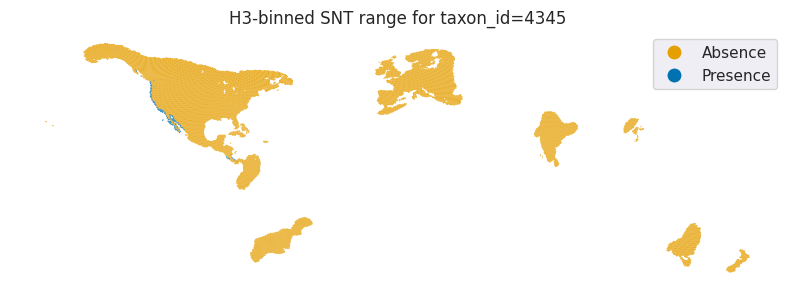

In [87]:
fig, ax = plt.subplots(figsize=(10, 6))
cmap = ListedColormap(["#E69F00", "#0072B2"])
gdf.plot(column="label", categorical=True, legend=True,
         cmap=cmap,
         ax=ax, alpha=1, edgecolor="none")
ax.set_title(f"H3-binned SNT range for taxon_id={target_taxon_id}")
ax.set_axis_off()
plt.show()

In [90]:
def map_snt_taxon(taxon_idx):
    target_taxon_id = species_ids[taxon_idx]
    cur_loc_indices = np.array(loc_indices_per_species[taxon_idx])
    y_test = np.array(labels_per_species[taxon_idx])
    taxon_obs_locs = obs_locs[cur_loc_indices]

    df = pd.DataFrame(taxon_obs_locs, columns=["lng", "lat"])
    df["label"] = y_test
    dfh3 = df.h3.geo_to_h3(h3_res)
    dfh3.reset_index(inplace=True)
    
    counts = dfh3.groupby(["h3_04", "label"]).size().unstack(fill_value=0).reset_index()
    counts.columns.name = None
    counts = counts.rename(columns={0: "absence", 1: "presence"})
    counts["dominant_label"] = counts["presence"] > counts["absence"]
    
    gdf = counts.set_index("h3_04").h3.h3_to_geo_boundary()
    gdf["label"] = gdf["dominant_label"].map({True: "Presence", False: "Absence"})
    
    fig, ax = plt.subplots(figsize=(10, 6))
    cmap = ListedColormap(["#E69F00", "#0072B2"])
    gdf.plot(column="label", categorical=True, legend=True,
             cmap=cmap, ax=ax, alpha=1, edgecolor="none")
    ax.set_title(f"H3-binned SNT range for taxon_id={target_taxon_id}")
    ax.set_axis_off()
    plt.show()

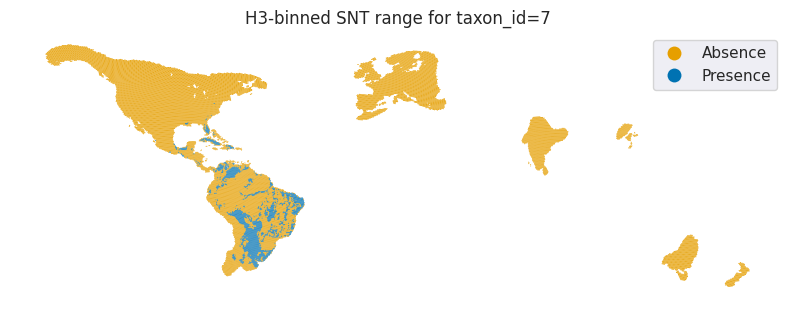

In [91]:
map_snt_taxon(0)

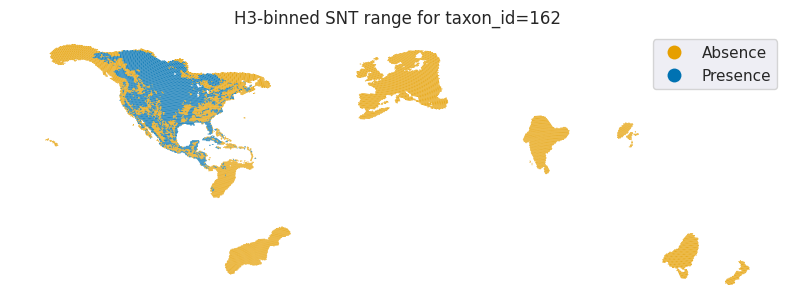

In [92]:
map_snt_taxon(1)